# 00 - Orientation and Setup

**Part A - Foundations - Petrophys Curriculum**

Welcome. This is the first lesson of the *petrophys* teaching curriculum. By the
end of it you will know what the library is for, how to reach the well-log data that
ships inside it, and where each later lesson fits into the bigger picture.

No prior experience with *petrophys* is assumed - only a working knowledge of basic
petrophysics (gamma ray, density, neutron, resistivity, porosity, water saturation).

## Learning goals

- Understand what *petrophys* is: a comprehensive, open well-log and
  formation-evaluation platform.
- Load the **bundled sample data** with `petrophys.sample(...)` and discover what is
  available with `petrophys.list_samples(...)`.
- Take a guided tour of the **two teaching datasets**:
  - *Geolink* - North Sea **clastic** wells (primary teaching well `30_6-5`).
  - *Costa* - a 17-well **carbonate** field (`HW-3 ... HW-32`).
- Read the **curriculum roadmap** (Parts A and B) so you know where you are going.
- Know honestly **what is not covered yet** so you set the right expectations.

## Why this matters

Formation evaluation is the discipline of turning raw borehole measurements into
answers a subsurface team can act on: *How much rock is reservoir? How porous is it?
How much of the pore space is hydrocarbon rather than water?*

The workflow always starts the same way - **get the data in, and understand it** -
before any physics is applied. This lesson is that starting point. Everything later
(clay volume, porosity, saturation, permeability, net pay, lithology solving) builds on
the `Well` and `Curve` objects you will meet here.

### Prerequisites and kernel setup

Use a Python kernel in which this checkout is installed. From the repository root, a project environment can be prepared with:

```powershell
py -m venv .venv
.\.venv\Scripts\python.exe -m pip install -e ".[tutorials]"
.\.venv\Scripts\python.exe -m ipykernel install --user --name petrophys
```

Select the **petrophys** kernel in your notebook editor. The commands are instructions, not notebook cells that change your environment automatically. A private clone requires repository access; Git must be installed and the terminal restarted if it is not found.

The small LAS examples are bundled with the package. Optional ML and native DLIS lessons have additional requirements. In the next cell, check which Python and package the kernel is actually using.

In [1]:
%matplotlib inline
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las

print('petrophys version:', petrophys.__version__)
print('Kernel Python:', sys.executable)
print('Package:', petrophys.__file__)
print('Ready. The small LAS teaching samples are bundled.')

petrophys version: 3.0.0
Kernel Python: [python environment]/bin/python
Package: [repository]/src/petrophys/__init__.py
Ready. The small LAS teaching samples are bundled.


### Start with a plot, not an interpretation

LAS alone is enough. Formations and lithology are optional, and plotting does not calculate missing SW. The later scientific lessons unpack the equations; the quickstart and [own-data notebook](../own_data.ipynb) teach the short user-facing workflow.

[repository]/src/petrophys/preprocessing/standardization/curve_standardizer.py:390: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]/src/petrophys/preprocessing/standardization/curve_standardizer.py:390: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


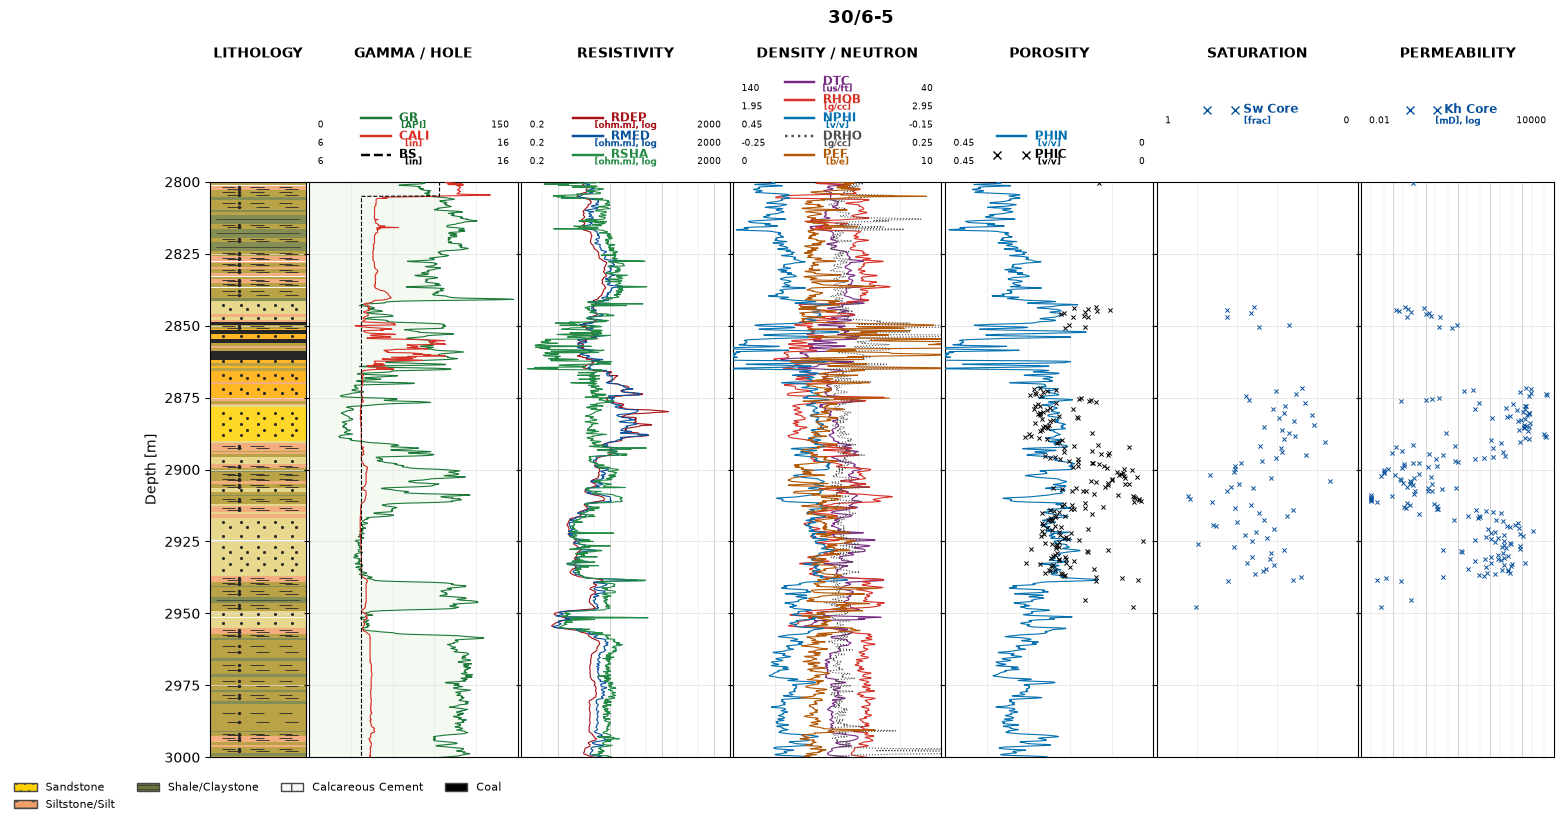

Plot diagnostics: ["SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units."]


In [2]:
import petrophys as pp
first_well = pp.read(pp.sample("30_6-5"))
first_plot = pp.plot(first_well, depth_range=(2800, 3000), figsize=(14, 8))
first_plot.show()
first_plot.close()
print("Plot diagnostics:", first_plot.warnings)

## 1. What is petrophys?

*petrophys* is a Python platform for **well-log analysis and formation evaluation**. It
covers the full path from a raw LAS/DLIS file to interpreted reservoir properties, and
groups its functionality into focused sub-packages. A high-level tour:

| Sub-package | Purpose |
|---|---|
| `petrophys.io` | Read/write well data (`read_las`, `read_dlis`, exporters) |
| `petrophys.model` | Core data model: the `Well` and `Curve` objects |
| `petrophys.preprocessing` | Quality control: standardization, bad-hole, value-range, normalization |
| `petrophys.interpretation.clay_volume` | Shale/clay volume from GR, SP, neutron-density |
| `petrophys.interpretation` | Porosity, saturation, permeability, cementation |
| `petrophys.interpretation.lithology` | Multi-mineral solving |
| `petrophys.evaluation` | Net pay, BVW, rock-quality index, flow units |
| `petrophys.evaluation.summaries` | Hydrocarbon pore volume, OOIP/OGIP, zone summaries |
| `petrophys.visualization` | Triple-combo, crossplots, Pickett, log viewers |

We will meet many of these across the curriculum. For now, the important idea is that
**every one of them consumes the same `Well` object** - so learning to load and inspect
a well (Part A) unlocks everything else.

In [3]:
# Discover the bundled sample catalogue.
all_samples = petrophys.list_samples()
geolink = petrophys.list_samples('geolink')
costa = petrophys.list_samples('costa')

print('Total bundled sample files :', len(all_samples))
print('Geolink (clastic)   :', geolink)
print('Costa   (carbonate) : %d wells -> %s ...' % (len(costa), costa[:4]))

Total bundled sample files : 31
Geolink (clastic)   : ['15_9-14', '16_7-1', '25_5-1', '30_6-5']
Costa   (carbonate) : 17 wells -> ['HW-10', 'HW-24', 'HW-25', 'HW-26'] ...


## 2. Accessing bundled data

Two functions are all you need to reach the sample data:

- `petrophys.list_samples(kind=None)` - returns the bundled sample file names: 21
  wells plus 3 CSV assets (formation tops and lithology for `30_6-5`, and an NMR
  dataset). Pass `'geolink'` or `'costa'` to filter by dataset, or nothing to list
  everything.
- `petrophys.sample(name)` - returns the **absolute path** to that well's LAS file. Feed
  that path straight into `read_las(...)`.

Because the data lives inside the installed package, this works on any machine with no
setup - no downloads, no credentials, no path juggling.

In [4]:
# sample() returns a filesystem path to the LAS file.
path_30_6_5 = petrophys.sample('30_6-5')
path_hw3 = petrophys.sample('HW-3')

print('30_6-5 LAS path:', path_30_6_5)
print('HW-3   LAS path:', path_hw3)

30_6-5 LAS path: [repository]/src/petrophys/datasets/geolink/30_6-5.las
HW-3   LAS path: [repository]/src/petrophys/datasets/costa/HW-3.las


## 3. Tour - dataset one: Geolink (North Sea clastics)

The **Geolink** wells are siliciclastic (sand/shale) wells from the Norwegian North
Sea. Our **primary teaching well is `30_6-5`** from the Oseberg area: it is unusually
rich, carrying not just the standard triple-combo logs but also core
porosity/permeability measurements and a supplied lithology track - ideal for teaching.

Let us load it and read off the basic facts.

In [5]:
w_geo = read_las(petrophys.sample('30_6-5'))

# header.field can contain non-ASCII field names; print an ASCII-safe version.
field_ascii = (w_geo.header.field or '').encode('ascii', 'replace').decode('ascii')

print('=== Geolink well 30_6-5 ===')
print('Well name    :', w_geo.name)
print('Field        :', field_ascii)
print('UWI          :', w_geo.header.uwi)
print('# curves     :', w_geo.n_curves)
print('# samples    :', w_geo.n_samples)
print('Depth unit   :', w_geo.depth_unit)
print('Depth range  : %.2f -> %.2f %s' % (w_geo.start_depth, w_geo.stop_depth, w_geo.depth_unit))
print('Sample step  : %.4f %s' % (w_geo.step, w_geo.depth_unit))
print()
print('Curves:')
print('  ' + ', '.join(w_geo.curves))

=== Geolink well 30_6-5 ===
Well name    : 30/6-5
Field        : OSEBERG ?ST
UWI          : 30/6-5
# curves     : 20
# samples    : 22176
Depth unit   : m
Depth range  : 176.61 -> 3556.08 m
Sample step  : 0.1524 m

Curves:
  LITHOLOGY_GEOLINK, CALI, DRHO, NPHI, RHOB, PEF, GR, DTC, DTE, RDEP, SP, RSHA, RMED, BS, PHIC, GDEN, KH_CORE, KV_CORE, SWC, SOC


Notice a few things about `30_6-5`:

- Depth is in **metres** (`m`) - a European convention.
- Alongside the classic logs (`GR`, `RHOB`, `NPHI`, `PEF`, `DTC`, resistivities `RDEP`,
  `RMED`, `RSHA`, `SP`) it carries **`CALI`** (caliper) and **`BS`** (bit size), which
  we will use for bad-hole detection in lesson 02.
- It has **core data**: `KH_CORE`/`KV_CORE` (horizontal/vertical permeability),
  `PHIC` (core porosity), plus `SWC`/`SOC`. Core-calibrated wells are gold for
  benchmarking log-derived answers.
- It even ships a supplied `LITHOLOGY_GEOLINK` track.

## 4. Tour - dataset two: Costa (carbonate field)

The **Costa** dataset is a 17-well **carbonate** field (`HW-3` through `HW-32`). Carbonate
petrophysics differs from clastics (complex pore systems, different lithology solving,
Archie parameters `a`, `m`, `n` that vary with texture), so having a carbonate field lets
the curriculum contrast the two rock types.

The Costa wells are leaner and more uniform than `30_6-5` - a realistic multi-well set for
teaching **normalization** across a field. Let us load `HW-3`.

In [6]:
w_car = read_las(petrophys.sample('HW-3'))

print('=== Costa well HW-3 ===')
print('Well name    :', w_car.name)
print('Field        :', w_car.header.field)
print('UWI          :', w_car.header.uwi)
print('# curves     :', w_car.n_curves)
print('# samples    :', w_car.n_samples)
print('Depth unit   :', w_car.depth_unit)
print('Depth range  : %.2f -> %.2f %s' % (w_car.start_depth, w_car.stop_depth, w_car.depth_unit))
print('Sample step  : %.4f %s' % (w_car.step, w_car.depth_unit))
print()
print('Curves:')
print('  ' + ', '.join(w_car.curves))

=== Costa well HW-3 ===
Well name    : HW-3
Field        : COSTA
UWI          : HW-3
# curves     : 8
# samples    : 431
Depth unit   : ft
Depth range  : 7805.00 -> 8020.00 ft
Sample step  : 0.5000 ft

Curves:
  GR, RHOB, NPHI, DT, PHIE_CC, RT, SW_INPUT, PERM_CC


Contrast with the Geolink well:

- Depth here is in **feet** (`ft`) - a North American convention. Mixed depth units across
  datasets is exactly why unit awareness (lesson 02) matters.
- The Costa curve set is compact: `GR`, `RHOB`, `NPHI`, `DT` (sonic), `RT` (true
  resistivity), plus **core-calibrated** `PHIE_CC` (effective porosity), `SW_INPUT`
  (water saturation) and `PERM_CC` (permeability).
- No caliper/bit-size here - so bad-hole detection (lesson 02) will be demonstrated on
  the Geolink well, and normalization on the Costa field.

Let us put the two side by side.

In [7]:
summary = pd.DataFrame([
    {'well': w_geo.name, 'dataset': 'Geolink (clastic)', 'rock': 'sand/shale',
     'depth_unit': w_geo.depth_unit, 'n_curves': w_geo.n_curves,
     'n_samples': w_geo.n_samples,
     'top': round(w_geo.start_depth, 1), 'base': round(w_geo.stop_depth, 1)},
    {'well': w_car.name, 'dataset': 'Costa (carbonate)', 'rock': 'carbonate',
     'depth_unit': w_car.depth_unit, 'n_curves': w_car.n_curves,
     'n_samples': w_car.n_samples,
     'top': round(w_car.start_depth, 1), 'base': round(w_car.stop_depth, 1)},
])
summary

,well,dataset,rock,depth_unit,n_curves,n_samples,top,base
0,30/6-5,Geolink (clastic),sand/shale,m,20,22176,176.6,3556.1
1,HW-3,Costa (carbonate),carbonate,ft,8,431,7805.0,8020.0


## 5. A first look at the logs

To make the two wells concrete, here is the gamma-ray log from each, plotted against
depth (log convention: depth increasing downward). GR distinguishes clean reservoir
(low GR) from shale/clay (high GR). Notice how different the two GR *scales* are - the
Costa carbonate reads far lower than the North Sea shales. That contrast is real
lithology, not a tool artifact. Multi-well **normalization** (lesson 02) solves a
different problem: correcting well-to-well calibration bias between wells of the
*same* field.

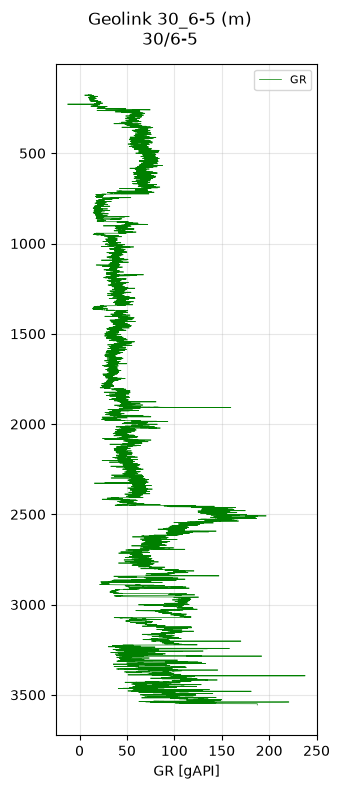

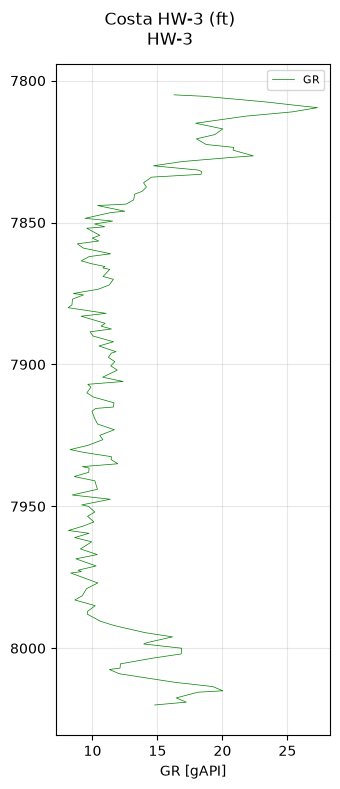

GR ranges -> Geolink: -13..238  |  Costa: 8..27


In [8]:
# GR first-look via the library LogPlot (one single-track plot per well,
# since the two wells are on different depth units - m vs ft).
from petrophys.visualization import LogPlot

for w, title in [(w_geo, 'Geolink 30_6-5 (m)'), (w_car, 'Costa HW-3 (ft)')]:
    lp = LogPlot(w, figsize=(3.5, 8))
    lp.create_figure(n_tracks=1)
    lp.add_curve(0, 'GR', color='green')
    lp.add_title(title)
    lp.show()

print('GR ranges -> Geolink: %.0f..%.0f  |  Costa: %.0f..%.0f'
      % (w_geo.get('GR').min(), w_geo.get('GR').max(),
         w_car.get('GR').min(), w_car.get('GR').max()))

## 6. Curriculum roadmap

The curriculum is split into two parts.

### Part A - Foundations & Core Science (you are here)
| # | Lesson | What you learn |
|---|---|---|
| 00 | Orientation and setup | This lesson: purpose, data, roadmap |
| 01 | Loading and inspecting data | The `Well` / `Curve` data model in depth |
| 02 | QA/QC and standardization | Conditioning: aliases, units, bad-hole, normalization |
| 03 | Clay volume | Vcl from GR (linear/Larionov/Steiber/Clavier), SP, neutron-density |
| 04 | Porosity | Density/neutron/sonic; total vs effective; hydrocarbon correction |
| 05 | Lithology and mineral solver | N-D/PEF crossplots; 2- and 3-mineral least-squares solving |
| 06 | Formation water and environment | Rw (SP/salinity), Rmf, temperature profile, invasion |
| 07 | Water saturation | Archie + shaly-sand models; Pickett m/n; model selection |
| 08 | Permeability | Timur/Coates; core poro-perm calibration |
| 09 | Reservoir quality and net pay | RQI/FZI/flow units; BVW/MHI; net pay; HCPV/OOIP/OGIP |

### Part B - Integrated & Advanced Workflows
Building on the foundations from Part A, Part B covers the integrated and specialist
workflows:

| # | Lesson | What you learn |
|---|---|---|
| 10 | Dynamic workflow (glass box) | Auto method selection, 18-step pipeline, step traces, overrides |
| 11 | Formation and interval analysis | Tops, zones/subzones, per-interval and formation summaries |
| 12 | Core calibration and digital core | Core-to-log calibration; digital-core facies, XRF, geomechanics |
| 13 | ML curve imputation | Pretrained model to impute missing curves, with confidence |
| 14 | NMR petrophysics | T2 bins; SDR and Coates permeability; BVI/FFI |
| 15 | Capillary pressure and saturation-height | J-function, Brooks-Corey fitting, Pc-height conversion |
| 16 | Borehole image (FMI) | Pads to oriented image, equalization, azimuthal coverage |
| 17 | Visualization masterclass | XML templates, adaptive viewer, crossplots, batch export |
| 18 | Multiwell field study | Costa 17-well batch, normalization, portfolio summary |

Each lesson consumes exactly the `Well` object you learn to build here in Part A.


## 7. What is NOT covered yet

To set honest expectations, the current curriculum focuses on **wireline log analysis and
formation evaluation**. The following are outside its present scope:

- **Seismic and AVO** - no seismic inversion, amplitude-versus-offset, or
  rock-physics-to-seismic tie.
- **Geomechanics** - beyond limited digital-core mechanical properties, no full wellbore
  stability / stress modelling.
- **Unconventionals / TOC** - no organic-richness (total organic carbon) or
  source-rock workflows.
- **4D (time-lapse)** - no repeat-survey / production monitoring.
- **Monte-Carlo uncertainty** - results here are deterministic; probabilistic
  uncertainty propagation is not part of this curriculum yet.

Knowing the boundary is part of using any tool responsibly.

## Pitfalls and good habits

- **Mind the depth unit.** Geolink is in metres, Costa in feet. Always read
  `w.depth_unit` before comparing depths or thicknesses across wells.
- **Use `sample()` for paths, never hard-code them.** The bundled data path differs by
  machine; `petrophys.sample(name)` resolves it for you.
- **Non-ASCII header fields happen.** Legacy LAS headers (like the Oseberg field name)
  can carry odd encodings; sanitize before printing if you need clean ASCII output.
- **Core curves are precious.** When a well carries `*_CORE` / `*_CC` curves, use them to
  validate your log-derived answers later in Part B.

## Recap

- *petrophys* is a comprehensive well-log / formation-evaluation platform; every
  sub-package consumes the same `Well` object.
- `petrophys.list_samples(...)` lists bundled wells; `petrophys.sample(name)` gives the
  LAS path to feed `pp.read(...)` (or the lower-level `read_las`).
- Two teaching datasets: **Geolink** North Sea clastics (primary well `30_6-5`, metres,
  core-rich) and **Costa** carbonates (`HW-3 ... HW-32`, feet).
- The curriculum runs Part A (lessons 00-09: foundations and the core
  interpretation science, from loading and QA/QC through saturation, permeability,
  and net pay) then Part B (lessons 10-18: integrated and advanced workflows).
- Seismic/AVO, full geomechanics, unconventionals/TOC, 4D, and Monte-Carlo uncertainty
  are explicitly out of scope for now.
- Start with read/plot; add `pp.interpret` only when ready to review its assumptions and trace. It copies the well by default.

## Try it yourself

> **Exercise 1.** Load a *second* Costa well (e.g. `HW-10`) and a *second* Geolink well
> (e.g. `15_9-14`). Print each well's name, curve count, depth unit and depth range. Do
> all Costa wells share the same curve set? Do they cover the same depth interval?
>
> **Exercise 2.** For any well, list which curves contain the substring `CORE` or `CC`
> (core-calibrated data). Which of the two datasets is richer in core control?

*Hint:* iterate over `petrophys.list_samples('costa')`, and use `read_las(petrophys.sample(name))`.

## What's next

Continue with **`01_loading_and_inspecting_data.ipynb`**, where we open up the `Well` and
`Curve` objects properly: headers, per-curve statistics, DataFrame export, depth slicing,
and the difference between the curve sets of a clastic and a carbonate well.